# Лабораторная работа № 2
## Разведочный и предиктивный анализ данных

**Дисциплина:** «Методы машинного обучения»  
**Вариант:** 5  
**Набор данных:** `scrap price.csv` (Car Price, 205 наблюдений × 26 признаков)

**Цель работы** — освоить инструменты сбора и подготовки данных средствами Python, Pandas, NumPy, Matplotlib и Scikit-learn: импортировать набор данных, проверить его на пропуски и аномальные значения, обработать их статистическими и графическими методами, сгенерировать новые признаки, выполнить кодирование категориальных признаков, стандартизацию и нормализацию, а также визуализировать результаты подготовки.

**Порядок выполнения:**

1. импорт набора данных и проверка пропусков;
2. обнаружение и устранение выбросов методом межквартильного размаха (IQR);
3. генерация новых признаков и кодирование категориальных признаков (OHE, порядковое кодирование, бинаризация);
4. стандартизация и нормализация данных;
5. графическая проверка результатов: пропуски, выбросы, распределения, корреляции, масштабирование.

> В отличие от настольной версии (`main.py` с интерфейсом на tkinter) ноутбук выводит графики прямо под ячейками, а в конце сохраняет их в папку `figures/`.

## 0. Импорт библиотек и настройка окружения

Путь к CSV определяется автоматически: файл ищется в текущей папке, в подпапке `lab2`, а также на один и два уровня выше — поэтому ноутбук работает и из корня проекта, и из папки `lab2`.

In [1]:
%matplotlib inline

import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110


def find_data_file(name='scrap price.csv'):
    """Ищет CSV рядом с ноутбуком, в подпапке lab2/ и на уровень выше."""
    here = Path.cwd()
    for base in (here, here / 'lab2', here.parent,
                 here.parent / 'lab2', here.parent.parent):
        candidate = base / name
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Файл {name!r} не найден. Положите его рядом с ноутбуком "
        f"или в папку lab2/ (текущая папка: {here})."
    )


CSV_PATH = find_data_file()
BASE_DIR = CSV_PATH.parent
FIG_DIR = BASE_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

print(f"Python:  {sys.version.split()[0]}")
print(f"pandas:  {pd.__version__} | numpy: {np.__version__}")
print(f"CSV:     {CSV_PATH}")
print(f"Графики: {FIG_DIR}")

Python:  3.9.13
pandas:  2.3.3 | numpy: 2.0.2
CSV:     C:\Users\User\Desktop\sem7\MMO\lab2\lab2\scrap price.csv
Графики: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures


## 1. Загрузка данных

Каждая строка описывает автомобиль: тип кузова, привод, тип двигателя, габариты, массу, мощность, расход топлива и цену. Целевой признак — `price`.

Столбцы `ID` (номер записи) и `name` (название модели, 147 уникальных значений на 205 строк) являются идентификаторами и не несут полезной информации для анализа, поэтому удаляются сразу после загрузки.

In [2]:
df = pd.read_csv(CSV_PATH)
rows_raw, cols_raw = df.shape
print(f"Исходные данные: {rows_raw} строк, {cols_raw} столбцов")

# ID и name — идентификаторы, а не признаки
df = df.drop(columns=[c for c in ('ID', 'name') if c in df.columns])
print(f"После удаления ID и name: {df.shape[0]} строк, {df.shape[1]} столбцов")

df.head()

Исходные данные: 205 строк, 26 столбцов
После удаления ID и name: 205 строк, 24 столбцов


,symboling,fueltypes,aspiration,doornumbers,carbody,drivewheels,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
print('Числовых признаков:      ', df.select_dtypes(include=[np.number]).shape[1])
print('Категориальных признаков:', df.select_dtypes(include=['object']).shape[1])
df.dtypes.value_counts()

Числовых признаков:       15
Категориальных признаков: 9


object     9
float64    8
int64      7
Name: count, dtype: int64

## 2. Проверка и заполнение пропусков

Пропуски (`NaN`) проверяются методом `isna()` с суммированием по столбцам. Числовые пропуски заполняются **медианой** — в отличие от среднего она устойчива к выбросам и лучше описывает типичное значение. Категориальные пропуски заполняются **модой** (наиболее частым значением). После заполнения выполняется повторная проверка.

В рассматриваемом наборе данных пропусков нет (0 до и 0 после), но правило заполнения реализовано — программа корректно обработает и файл с пропущенными значениями.

In [4]:
missing_before = df.isna().sum()
print(f"Пропуски до обработки: {int(missing_before.sum())}")
cols_na = missing_before[missing_before > 0]
print('Столбцы с пропусками:', cols_na.to_dict() if len(cols_na) else 'нет')


def fill_missing(frame):
    """Числовые пропуски — медианой, категориальные — модой."""
    frame = frame.copy()
    for col in frame.select_dtypes(include=[np.number]).columns:
        if frame[col].isna().any():
            frame[col] = frame[col].fillna(frame[col].median())
    for col in frame.select_dtypes(include=['object']).columns:
        if frame[col].isna().any():
            frame[col] = frame[col].fillna(frame[col].mode().iloc[0])
    return frame


df = fill_missing(df)
print(f"Пропуски после обработки: {int(df.isna().sum().sum())}")

Пропуски до обработки: 0
Столбцы с пропусками: нет
Пропуски после обработки: 0


## 3. Обнаружение и устранение выбросов (метод IQR)

Межквартильный размах: `IQR = Q3 − Q1`, границы `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]`. Всё, что выходит за границы, считается выбросом (правило Тьюки).

- Для **ключевых** признаков `price`, `horsepower`, `enginesize`, `curbweight` строки-выбросы **удаляются**. Процедура повторяется до стабилизации: после удаления строк квартили пересчитываются, поэтому одного прохода недостаточно.
- Для **вторичных** непрерывных признаков (`wheelbase`, `carlength`, `carwidth`, `carheight`, `boreratio`, `stroke`, `compressionratio`, `peakrpm`, `citympg`, `highwaympg`) применяется **winsorization** — значения ограничиваются границами IQR. Строки при этом сохраняются.

In [5]:
outlier_drop_cols = ['price', 'horsepower', 'enginesize', 'curbweight']
outlier_clip_cols = ['wheelbase', 'carlength', 'carwidth', 'carheight',
                     'boreratio', 'stroke', 'compressionratio', 'peakrpm',
                     'citympg', 'highwaympg']
outlier_check_cols = outlier_drop_cols + outlier_clip_cols


def iqr_bounds(series):
    """Границы Тьюки: Q1 - 1.5*IQR и Q3 + 1.5*IQR."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def count_outliers(frame, col):
    lower, upper = iqr_bounds(frame[col])
    return int(((frame[col] < lower) | (frame[col] > upper)).sum())


df_clean = df.copy()

# 1) Удаление строк с выбросами по ключевым признакам — до стабилизации
removed_total = 0
for _ in range(10):
    rows_before = len(df_clean)
    mask = pd.Series(False, index=df_clean.index)
    for col in outlier_drop_cols:
        lower, upper = iqr_bounds(df_clean[col])
        mask |= (df_clean[col] < lower) | (df_clean[col] > upper)
    df_clean = df_clean[~mask].copy()
    if len(df_clean) == rows_before:
        break
    removed_total += rows_before - len(df_clean)

# 2) Ограничение (winsorization) вторичных непрерывных признаков
for _ in range(10):
    changed = False
    for col in outlier_clip_cols:
        lower, upper = iqr_bounds(df_clean[col])
        clipped = df_clean[col].clip(lower, upper)
        if not clipped.equals(df_clean[col]):
            df_clean[col] = clipped
            changed = True
    if not changed:
        break

remaining_outliers = {col: count_outliers(df_clean, col) for col in outlier_check_cols}
print(f"Удалено строк с выбросами: {removed_total} (осталось {len(df_clean)})")
print(f"Осталось выбросов (IQR): {sum(remaining_outliers.values())}")

assert sum(remaining_outliers.values()) == 0, "Выбросы не устранены"
assert df_clean.isna().sum().sum() == 0, "После очистки остались пропуски"

Удалено строк с выбросами: 19 (осталось 186)
Осталось выбросов (IQR): 0


In [6]:
# Границы IQR после очистки (для проверки и отчёта)
pd.DataFrame(
    {col: iqr_bounds(df_clean[col]) for col in outlier_check_cols},
    index=['нижняя граница', 'верхняя граница'],
).T.round(2)

,нижняя граница,верхняя граница
price,-2627.25,24722.75
horsepower,4.75,178.75
enginesize,41.50,189.50
curbweight,1093.38,3840.38
wheelbase,85.65,109.25
carlength,149.05,195.05
carwidth,60.25,70.25
carheight,46.75,60.75
boreratio,2.44,4.19
stroke,2.67,3.85


## 4. Генерация новых признаков

Модель видит только числа, поэтому полезно дать ей отношения исходных характеристик — они отражают свойства автомобиля, которых нет в отдельных столбцах.

| Признак | Формула | Содержательный смысл |
|---|---|---|
| `power_to_weight` | horsepower / curbweight | удельная мощность на единицу массы |
| `engine_per_cylinder` | enginesize / cylinders | рабочий объём на один цилиндр |
| `avg_mpg` | (citympg + highwaympg) / 2 | средний расход топлива в двух режимах |
| `car_volume` | carlength · carwidth · carheight | габаритный объём кузова |
| `hp_per_liter` | horsepower / enginesize | литровая мощность двигателя |

Число цилиндров — **порядковый** признак, поэтому `cylindernumber` переводится в числа (`two → 2, …, twelve → 12`).

In [7]:
CYLINDERS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
             'six': 6, 'eight': 8, 'twelve': 12}

df_feat = df_clean.copy()
df_feat['cylinders'] = df_feat['cylindernumber'].map(CYLINDERS)

if df_feat['cylinders'].isna().any():
    unknown = sorted(df_feat.loc[df_feat['cylinders'].isna(), 'cylindernumber'].unique())
    raise ValueError(f"Неизвестное число цилиндров: {unknown}")
df_feat = df_feat.drop(columns=['cylindernumber'])

df_feat['power_to_weight'] = df_feat['horsepower'] / df_feat['curbweight']
df_feat['engine_per_cylinder'] = df_feat['enginesize'] / df_feat['cylinders']
df_feat['avg_mpg'] = (df_feat['citympg'] + df_feat['highwaympg']) / 2
df_feat['car_volume'] = df_feat['carlength'] * df_feat['carwidth'] * df_feat['carheight']
df_feat['hp_per_liter'] = df_feat['horsepower'] / df_feat['enginesize']

new_features = ['power_to_weight', 'engine_per_cylinder', 'avg_mpg',
                'car_volume', 'hp_per_liter']
print(f"Сгенерировано новых признаков: {len(new_features)} -> {new_features}")
df_feat[new_features].describe().round(4)

Сгенерировано новых признаков: 5 -> ['power_to_weight', 'engine_per_cylinder', 'avg_mpg', 'car_volume', 'hp_per_liter']


,power_to_weight,engine_per_cylinder,avg_mpg,car_volume,hp_per_liter
count,186.0000,186.0000,186.0000,186.0000,186.0000
mean,0.0388,28.2849,28.8468,609519.7730,0.8218
std,0.0075,4.7522,6.2350,70590.1536,0.1790
min,0.0199,19.7500,18.5000,478146.4380,0.5091
25%,0.0341,24.2500,24.5000,564657.3615,0.7143
50%,0.0374,27.2500,28.2500,601053.4400,0.7798
75%,0.0436,30.5000,34.0000,656215.3500,0.8806
max,0.0601,40.0000,49.0000,783141.3540,1.6875


## 5. Кодирование категориальных признаков

**Номинальные** признаки не имеют порядка, поэтому кодируются методом **One-Hot Encoding**: каждый столбец заменяется набором бинарных индикаторов. Параметр `drop_first=True` удаляет по одному индикатору из каждой группы, чтобы избежать ловушки фиктивных переменных (идеальной линейной зависимости между столбцами).

Параметр `dtype=float` принципиально важен: в Pandas 2.x `get_dummies` по умолчанию создаёт столбцы типа `bool`, которые не попадают в `select_dtypes(include=[np.number])` и могли бы выпасть из масштабирования.

**Бинаризация**: `high_power` = 1, если мощность выше медианы, иначе 0; `expensive_car` = 1, если цена выше медианы. `expensive_car` — производная от целевой переменной, поэтому формируется для анализа, но в матрицу признаков `X` не включается (иначе — утечка целевой переменной).

In [8]:
nominal_cols = ['fueltypes', 'aspiration', 'doornumbers', 'carbody',
                'drivewheels', 'enginelocation', 'enginetype', 'fuelsystem']

df_encoded = pd.get_dummies(df_feat, columns=nominal_cols,
                            drop_first=True, dtype=float)
print(f"После OHE-кодирования: {df_encoded.shape[1]} признаков")

ohe_cols = [c for c in df_encoded.columns
            if any(c.startswith(f'{n}_') for n in nominal_cols)]
print(f"Индикаторов OHE: {len(ohe_cols)}")
print(ohe_cols)

После OHE-кодирования: 42 признаков
Индикаторов OHE: 21
['fueltypes_gas', 'aspiration_turbo', 'doornumbers_two', 'carbody_hardtop', 'carbody_hatchback', 'carbody_sedan', 'carbody_wagon', 'drivewheels_fwd', 'drivewheels_rwd', 'enginetype_l', 'enginetype_ohc', 'enginetype_ohcf', 'enginetype_ohcv', 'enginetype_rotor', 'fuelsystem_2bbl', 'fuelsystem_4bbl', 'fuelsystem_idi', 'fuelsystem_mfi', 'fuelsystem_mpfi', 'fuelsystem_spdi', 'fuelsystem_spfi']


In [9]:
# Признаки, ставшие константными после очистки (OHE по ним не даёт индикаторов)
constant_cols = [c for c in nominal_cols if df_feat[c].nunique() <= 1]
print('Константные категориальные признаки:', constant_cols or 'нет')
for col in constant_cols:
    print(f"  {col}: единственное значение = {df_feat[col].iloc[0]!r}")

# Бинаризация по медиане
median_hp = df_encoded['horsepower'].median()
df_encoded['high_power'] = (df_encoded['horsepower'] > median_hp).astype(int)

median_price = df_encoded['price'].median()
# expensive_car — метка, производная от целевой переменной (в X не войдёт)
df_encoded['expensive_car'] = (df_encoded['price'] > median_price).astype(int)

print(f"Медиана мощности: {median_hp:.1f} -> high_power: "
      f"{int(df_encoded['high_power'].sum())} из {len(df_encoded)}")
print(f"Медиана цены:     {median_price:.1f} -> expensive_car: "
      f"{int(df_encoded['expensive_car'].sum())} из {len(df_encoded)}")

Константные категориальные признаки: ['enginelocation']
  enginelocation: единственное значение = 'front'
Медиана мощности: 91.0 -> high_power: 93 из 186
Медиана цены:     9767.0 -> expensive_car: 93 из 186


## 6. Матрица признаков

В `X` не включаются:

- `price` — целевая переменная;
- `expensive_car` — производная от цели (утечка целевой переменной).

Признак `high_power` остаётся: это допустимая бинарная характеристика автомобиля, не связанная с ценой.

In [10]:
target_related = ['price', 'expensive_car']

X = df_encoded.drop(columns=target_related)
X_numeric = X.select_dtypes(include=[np.number, 'bool']).astype(float)
y = df_encoded['price']

assert X_numeric.isna().sum().sum() == 0, "В матрице признаков есть пропуски"
print(f"Матрица признаков X: {X_numeric.shape[0]} строк, {X_numeric.shape[1]} признаков")
print(f"Целевая переменная y: {y.shape[0]} значений, "
      f"среднее {y.mean():.0f}, медиана {y.median():.0f}")

Матрица признаков X: 186 строк, 42 признаков
Целевая переменная y: 186 значений, среднее 11210, медиана 9767


In [11]:
binary_cols = [c for c in X_numeric.columns if X_numeric[c].nunique() == 2]

print('Все столбцы приведены к float64:', bool((X_numeric.dtypes == 'float64').all()))
print('Бинарных признаков (0/1):        ', len(binary_cols))
print('Столбцов с пропусками:           ', int(X_numeric.isna().any().sum()))

# Описательные статистики части признаков
X_numeric[binary_cols[:4] + ['horsepower', 'enginesize', 'curbweight',
                             'power_to_weight', 'hp_per_liter']].describe().round(3)

Все столбцы приведены к float64: True
Бинарных признаков (0/1):         22
Столбцов с пропусками:            0


,fueltypes_gas,aspiration_turbo,doornumbers_two,carbody_hardtop,horsepower,enginesize,curbweight,power_to_weight,hp_per_liter
count,186.000,186.000,186.000,186.000,186.000,186.000,186.000,186.000,186.000
mean,0.914,0.172,0.430,0.022,96.263,117.038,2458.640,0.039,0.822
std,0.281,0.378,0.496,0.145,29.403,25.417,424.539,0.008,0.179
min,0.000,0.000,0.000,0.000,48.000,61.000,1488.000,0.020,0.509
25%,1.000,0.000,0.000,0.000,70.000,97.000,2123.500,0.034,0.714
50%,1.000,0.000,0.000,0.000,91.000,110.000,2385.000,0.037,0.780
75%,1.000,0.000,1.000,0.000,113.500,134.000,2810.250,0.044,0.881
max,1.000,1.000,1.000,1.000,175.000,181.000,3485.000,0.060,1.688


## 7. Масштабирование: StandardScaler и MinMaxScaler

- **StandardScaler**: `z = (x − μ) / σ` — нулевое среднее, единичное стандартное отклонение, значения обычно в диапазоне −3…3.
- **MinMaxScaler**: `x' = (x − x_min) / (x_max − x_min)` — значения строго в отрезке [0, 1]; чувствителен к выбросам.

Масштабирование необходимо, поскольку признаки измеряются в разных единицах: цена — десятками тысяч, удельная мощность — десятыми долями. Без него признаки с большим разбросом доминировали бы в метриках расстояния и в регуляризованных моделях.

Масштабируются все 42 признака, включая бинарные индикаторы, приведённые к `float`.

In [12]:
X_standardized = pd.DataFrame(
    StandardScaler().fit_transform(X_numeric),
    columns=X_numeric.columns,
    index=X_numeric.index,
)
X_normalized = pd.DataFrame(
    MinMaxScaler().fit_transform(X_numeric),
    columns=X_numeric.columns,
    index=X_numeric.index,
)

sample_cols = ['horsepower', 'enginesize', 'curbweight']
summary = pd.concat({
    'исходные': X_numeric[sample_cols].describe().loc[['mean', 'std', 'min', 'max']],
    'StandardScaler': X_standardized[sample_cols].describe().loc[['mean', 'std', 'min', 'max']],
    'MinMaxScaler': X_normalized[sample_cols].describe().loc[['mean', 'std', 'min', 'max']],
}, axis=1).round(3)
summary

исходные                       StandardScaler                       MinMaxScaler                      
     horsepower enginesize curbweight     horsepower enginesize curbweight   horsepower enginesize curbweight
mean     96.263    117.038   2458.640         -0.000      0.000      0.000        0.380      0.467      0.486
std      29.403     25.417    424.539          1.003      1.003      1.003        0.232      0.212      0.213
min      48.000     61.000   1488.000         -1.646     -2.211     -2.293        0.000      0.000      0.000
max     175.000    181.000   3485.000          2.685      2.523      2.424        1.000      1.000      1.000

## 8. Функции построения графиков

Те же шесть графиков, что и в настольной версии, но без tkinter: функции возвращают объект `Figure`, а вывод в ноутбуке выполняет `plt.show()`. Реестр `PLOTS` используется в конце для сохранения всех графиков в файлы.

In [13]:
FIG_W, FIG_H = 10.0, 7.0


def plot_boxplots_comparison():
    """1. BoxPlot: ключевые признаки до и после устранения выбросов."""
    fig, axes = plt.subplots(2, 4, figsize=(FIG_W, FIG_H))
    for i, col in enumerate(outlier_drop_cols):
        axes[0, i].boxplot(df[col].dropna())
        axes[0, i].set_title(f'{col}\nДО очистки', fontsize=9)
        axes[1, i].boxplot(df_clean[col].dropna())
        axes[1, i].set_title(f'{col}\nПОСЛЕ', fontsize=9)
    fig.suptitle('BoxPlot: устранение выбросов (IQR)', fontsize=12)
    fig.tight_layout()
    return fig


def plot_boxplots_after():
    """2. BoxPlot всех непрерывных признаков после очистки."""
    fig, axes = plt.subplots(4, 4, figsize=(FIG_W, FIG_H))
    axes = axes.flatten()
    for ax in axes:
        ax.set_visible(False)
    for ax, col in zip(axes, outlier_check_cols):
        ax.set_visible(True)
        ax.boxplot(df_clean[col])
        ax.set_title(col, fontsize=9)
    fig.suptitle('BoxPlot после очистки: выбросов не обнаружено (IQR)',
                 fontsize=12)
    fig.tight_layout()
    return fig


def plot_distributions():
    """3. Гистограммы распределений ключевых числовых признаков."""
    dist_cols = ['price', 'horsepower', 'enginesize',
                 'curbweight', 'citympg', 'highwaympg']
    fig, axes = plt.subplots(2, 3, figsize=(FIG_W, FIG_H))
    axes = axes.flatten()
    for i, col in enumerate(dist_cols):
        axes[i].hist(df_clean[col].dropna(), bins=20, color='steelblue',
                     edgecolor='black', alpha=0.7)
        axes[i].set_title(f'Распределение {col}', fontsize=9)
        axes[i].set_ylabel('Частота', fontsize=8)
        axes[i].set_xlabel(col, fontsize=8)
    fig.suptitle('Распределения числовых признаков', fontsize=12)
    fig.tight_layout()
    return fig


def plot_correlation():
    """4. Тепловая карта корреляций числовых признаков."""
    corr = df_clean.select_dtypes(include=[np.number]).corr()
    fig, ax = plt.subplots(figsize=(FIG_W, 8.0))
    im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=9)
    ax.set_yticklabels(corr.columns, fontsize=9)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f'{corr.values[i, j]:.2f}',
                    ha='center', va='center', fontsize=9.5, color='black')
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title('Тепловая карта корреляций (после очистки)')
    fig.tight_layout()
    return fig


def plot_scaling_comparison():
    """5. Сравнение распределений до/после масштабирования."""
    cols = ['horsepower', 'enginesize', 'curbweight']
    fig, axes = plt.subplots(3, 3, figsize=(FIG_W, FIG_H))
    for i, col in enumerate(cols):
        axes[i, 0].hist(X_numeric[col], bins=15, color='blue',
                        alpha=0.7, edgecolor='black')
        axes[i, 0].set_title(f'{col} — исходные', fontsize=8)
        axes[i, 1].hist(X_standardized[col], bins=15, color='green',
                        alpha=0.7, edgecolor='black')
        axes[i, 1].set_title(f'{col} — StandardScaler', fontsize=8)
        axes[i, 2].hist(X_normalized[col], bins=15, color='red',
                        alpha=0.7, edgecolor='black')
        axes[i, 2].set_title(f'{col} — MinMaxScaler', fontsize=8)
    fig.suptitle('Сравнение масштабирования', fontsize=12)
    fig.tight_layout()
    return fig


def plot_missing_values():
    """6. Пропуски в данных до и после обработки."""
    missing_after = df_clean.isna().sum().reindex(missing_before.index).fillna(0)
    labels = list(missing_before.index)
    x = np.arange(len(labels))
    width = 0.4

    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
    ax.bar(x - width / 2, missing_before.values, width,
           label='До обработки', color='indianred')
    ax.bar(x + width / 2, missing_after.values, width,
           label='После обработки', color='seagreen')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_ylabel('Количество пропусков')
    ax.set_ylim(0, max(1.0, float(missing_before.max()) * 1.2))
    ax.legend()

    total_before = int(missing_before.sum())
    total_after = int(missing_after.sum())
    ax.set_title(f'Пропуски в данных: до — {total_before}, '
                 f'после — {total_after}', fontsize=12)
    if total_before == 0 and total_after == 0:
        ax.text(0.5, 0.5, 'Пропусков не обнаружено',
                transform=ax.transAxes, ha='center', va='center',
                fontsize=14, color='#2e7d32')
    fig.tight_layout()
    return fig


# Реестр графиков: название, функция, имя файла по умолчанию
PLOTS = [
    ("1. BoxPlot: выбросы (до/после)",         plot_boxplots_comparison, "01_boxplots.png"),
    ("2. BoxPlot: все признаки после очистки", plot_boxplots_after,      "02_boxplots_after.png"),
    ("3. Распределения признаков",             plot_distributions,       "03_distributions.png"),
    ("4. Тепловая карта корреляций",           plot_correlation,         "04_correlation.png"),
    ("5. Сравнение масштабирования",           plot_scaling_comparison,  "05_scaling.png"),
    ("6. Пропуски данных (до/после)",          plot_missing_values,      "06_missing.png"),
]
print('Зарегистрировано графиков:', len(PLOTS))

Зарегистрировано графиков: 6


## 9. Корреляционный анализ

Коэффициент корреляции Пирсона: `r = cov(x, y) / (σx · σy)`, значения от −1 до 1. Корреляция измеряет только **линейную** связь, и сильная корреляция не означает причинно-следственной зависимости. Матрица считается по очищенным данным; масштабирование на коэффициент Пирсона не влияет.

In [14]:
corr = df_clean.select_dtypes(include=[np.number]).corr()

corr['price'].sort_values(ascending=False).round(3).to_frame('r с price')

,r с price
price,1.000
curbweight,0.835
carwidth,0.766
horsepower,0.749
carlength,0.748
enginesize,0.713
wheelbase,0.684
boreratio,0.491
carheight,0.234
stroke,0.036


In [15]:
pairs = [('curbweight', 'price'), ('carwidth', 'price'),
         ('horsepower', 'price'), ('carlength', 'price'),
         ('enginesize', 'price'), ('citympg', 'highwaympg'),
         ('horsepower', 'highwaympg'), ('curbweight', 'highwaympg')]

pd.Series({f'{a} — {b}': corr.loc[a, b] for a, b in pairs}).round(3).to_frame('r')

,r
curbweight — price,0.835
carwidth — price,0.766
horsepower — price,0.749
carlength — price,0.748
enginesize — price,0.713
citympg — highwaympg,0.972
horsepower — highwaympg,-0.808
curbweight — highwaympg,-0.764


**Выводы по корреляциям.** Наиболее сильные положительные связи с ценой: `curbweight` (0,835), `carwidth` (0,766), `horsepower` (0,749), `carlength` (0,748), `enginesize` (0,713) — более крупные, тяжёлые и мощные автомобили в среднем дороже. Очень сильная связь `citympg` — `highwaympg` (0,972) означает дублирование информации (мультиколлинеарность): для линейной модели один из этих признаков можно убрать. Отрицательные связи мощности и цены с расходом топлива (около −0,81 и −0,70) отражают известную закономерность: мощные и тяжёлые автомобили расходуют больше топлива.

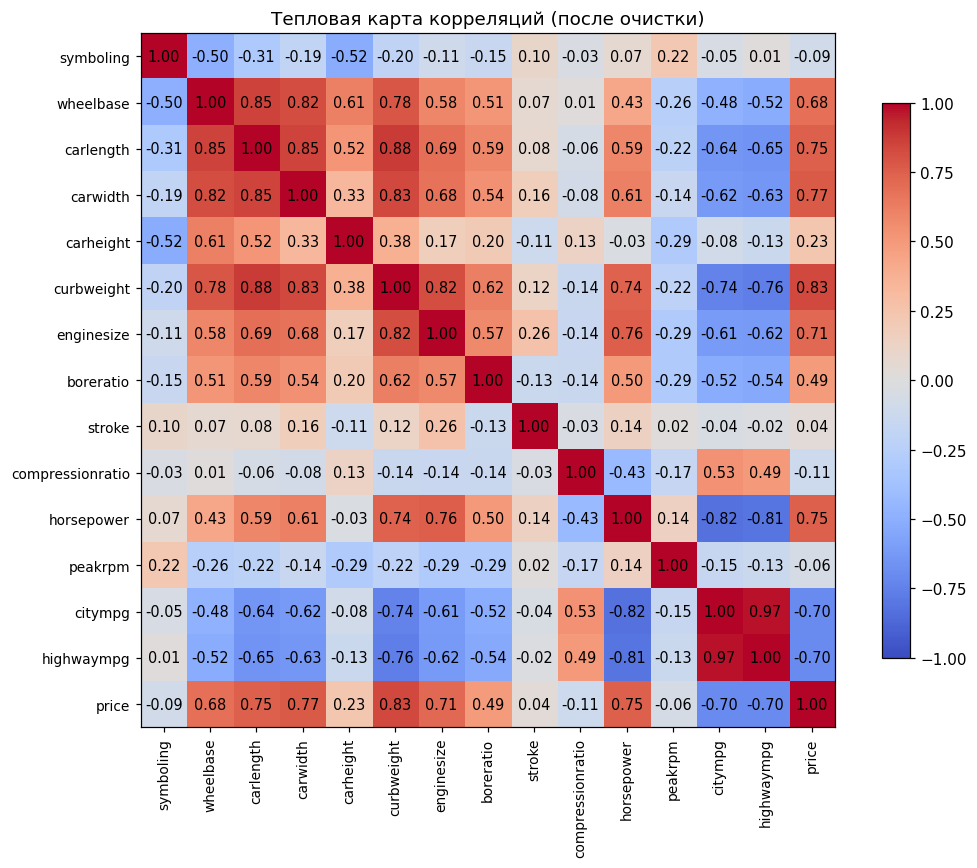

In [16]:
fig = plot_correlation()
plt.show()

## 10. Визуализация остальных результатов

**1. BoxPlot ключевых признаков до и после очистки** — точки за пределами «усов» до обработки и их отсутствие после.

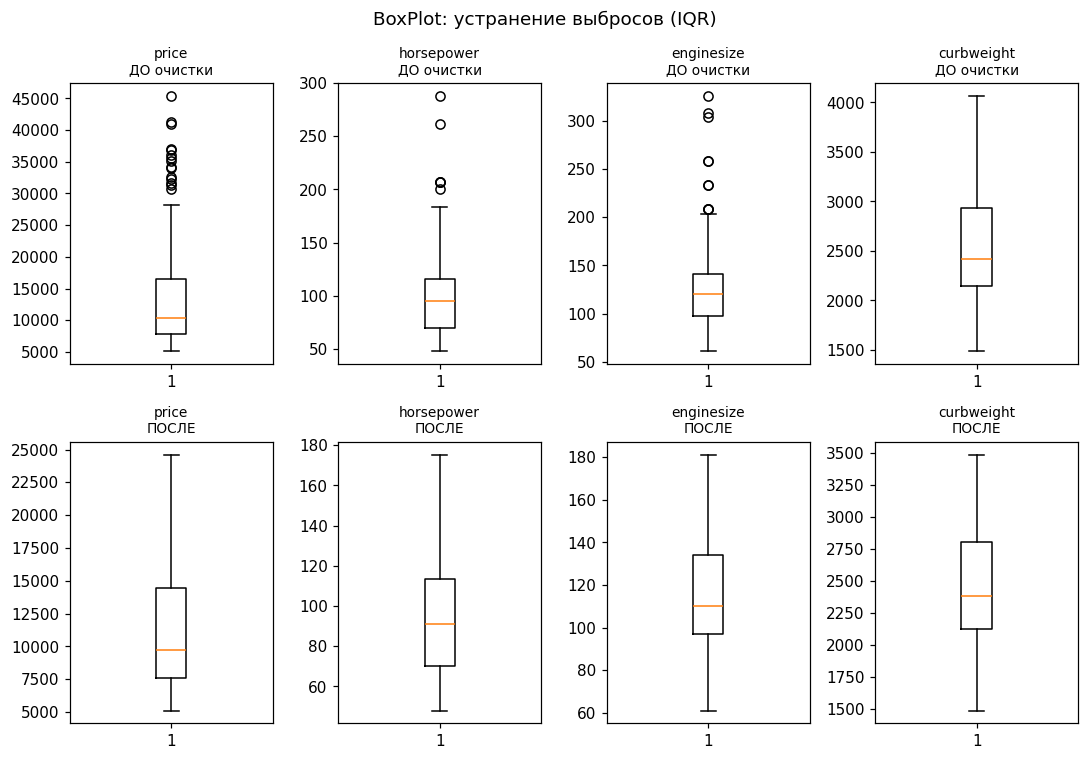

In [17]:
fig = plot_boxplots_comparison()
plt.show()

**2. BoxPlot всех 14 непрерывных признаков после очистки** — подтверждение, что выбросов не осталось ни у одного признака.

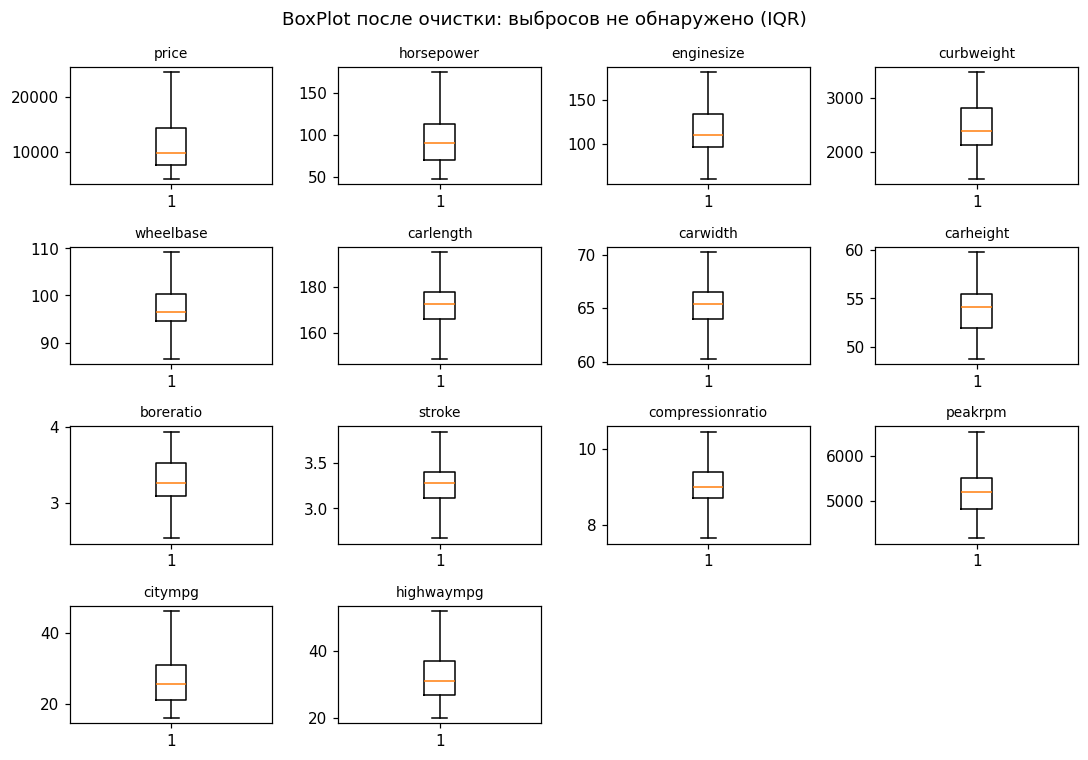

In [18]:
fig = plot_boxplots_after()
plt.show()

**3. Гистограммы распределений** — форма распределений; у цены выраженная правосторонняя асимметрия.

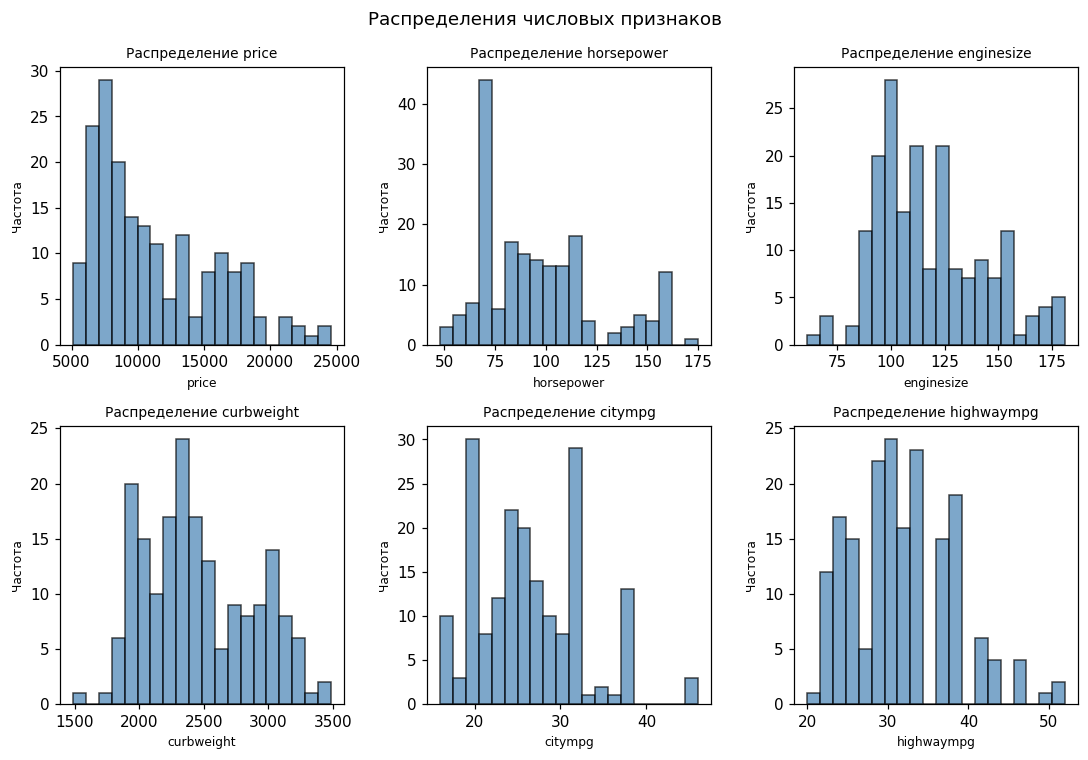

In [19]:
fig = plot_distributions()
plt.show()

**4. Сравнение масштабирования**: исходные значения, StandardScaler (центрирование, σ = 1) и MinMaxScaler (диапазон [0, 1]). Форма распределения сохраняется, меняется только масштаб оси.

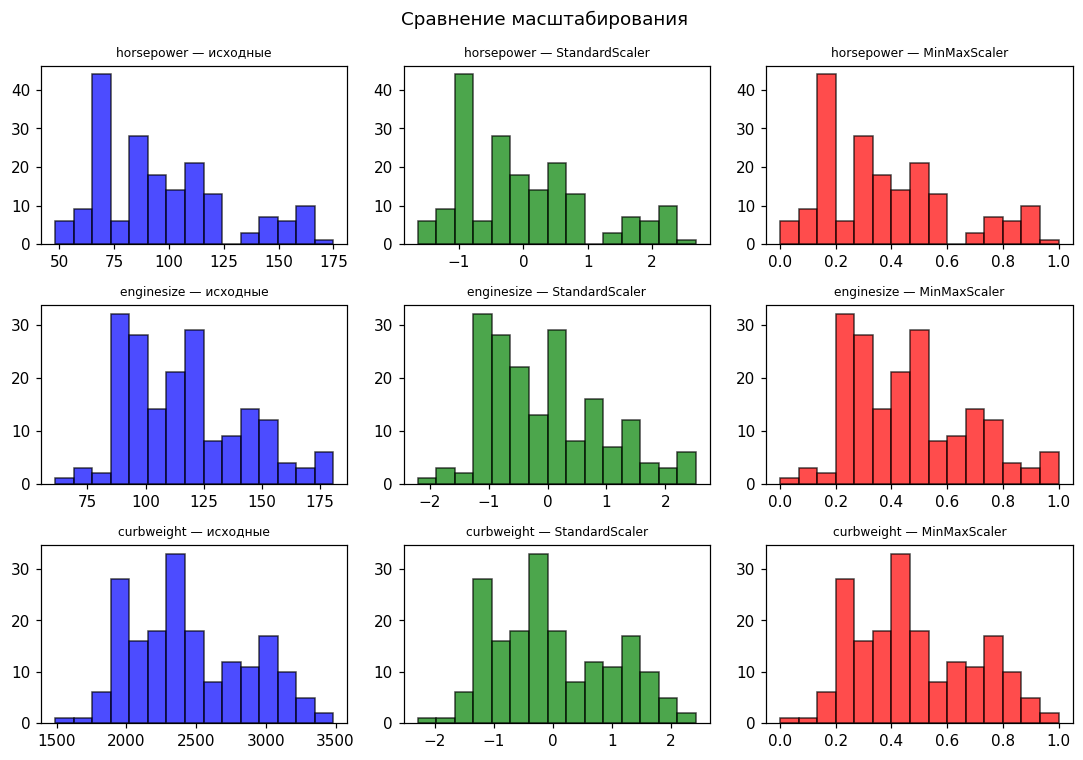

In [20]:
fig = plot_scaling_comparison()
plt.show()

**5. Пропуски до и после обработки** — визуальное подтверждение, что их количество равно нулю.

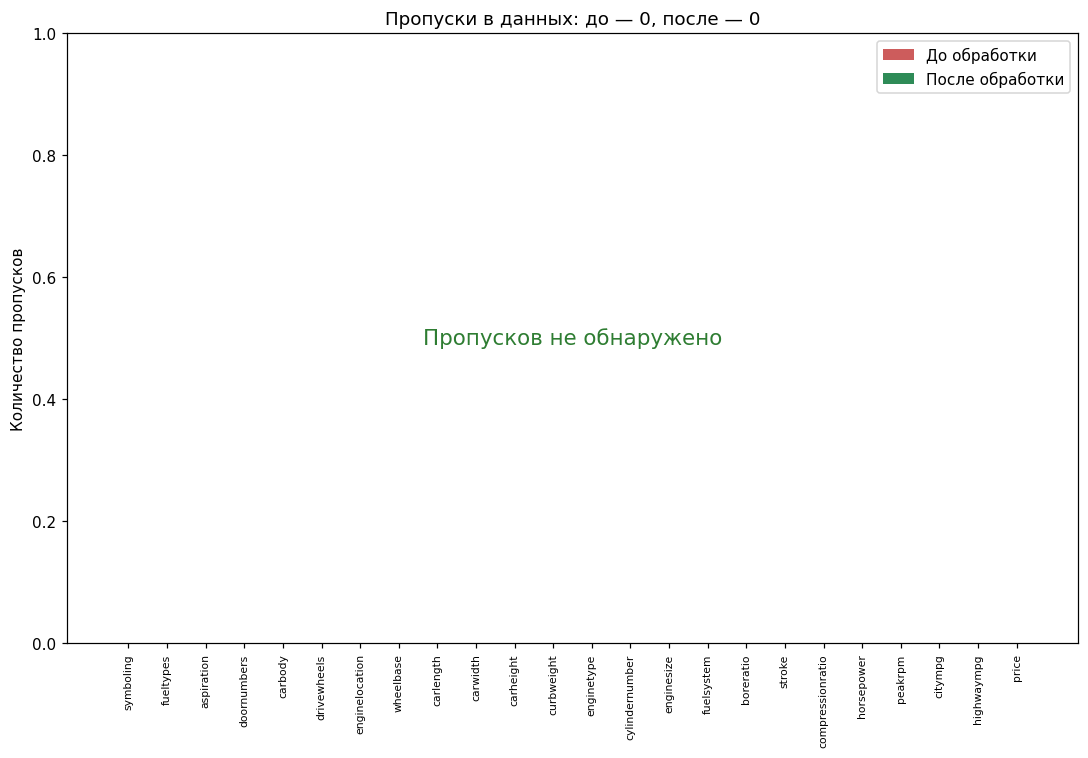

In [21]:
fig = plot_missing_values()
plt.show()

## 11. Сохранение графиков

Все шесть графиков сохраняются в папку `figures/` с разрешением 200 dpi и обрезанными полями (`bbox_inches='tight'`).

In [22]:
saved_files = []
for name, func, filename in PLOTS:
    fig = func()
    path = FIG_DIR / filename
    fig.savefig(path, dpi=200, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    saved_files.append(path)
    print(f"Сохранено: {path}")

print(f"\nВсего сохранено {len(saved_files)} графиков в {FIG_DIR}")

Сохранено: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures\01_boxplots.png


Сохранено: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures\02_boxplots_after.png


Сохранено: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures\03_distributions.png


Сохранено: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures\04_correlation.png


Сохранено: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures\05_scaling.png


Сохранено: C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures\06_missing.png

Всего сохранено 6 графиков в C:\Users\User\Desktop\sem7\MMO\lab2\lab2\figures


## 12. Итоговая сводка

Основные количественные результаты подготовки данных.

In [23]:
ohe_count = len([c for c in X_numeric.columns
                 if any(c.startswith(f'{n}_') for n in nominal_cols)])

summary_table = pd.DataFrame({
    'Показатель': [
        'Исходный размер набора',
        'Признаков после удаления ID и name',
        'Пропусков до / после обработки',
        'Удалено строк с выбросами',
        'Размер после очистки',
        'Выбросов после очистки (IQR)',
        'Сгенерировано новых признаков',
        'Столбцов после OHE и бинаризации',
        'Индикаторов OHE',
        'Матрица признаков X',
        'Масштабировано признаков',
        'Средняя цена',
        'Медиана цены',
        'Минимум / максимум цены',
    ],
    'Значение': [
        f'{rows_raw} × {cols_raw}',
        f'{df.shape[1]}',
        f'{int(missing_before.sum())} / {int(df.isna().sum().sum())}',
        f'{removed_total}',
        f'{len(df_clean)} × {df_clean.shape[1]}',
        f'{sum(remaining_outliers.values())}',
        f'{len(new_features)}',
        f'{df_encoded.shape[1]}',
        f'{ohe_count}',
        f'{X_numeric.shape[0]} × {X_numeric.shape[1]}',
        f'{X_numeric.shape[1]}',
        f'{y.mean():.0f}',
        f'{y.median():.0f}',
        f'{y.min():.0f} / {y.max():.0f}',
    ],
})
summary_table

,Показатель,Значение
0,Исходный размер набора,205 × 26
1,Признаков после удаления ID и name,24
2,Пропусков до / после обработки,0 / 0
3,Удалено строк с выбросами,19
4,Размер после очистки,186 × 24
5,Выбросов после очистки (IQR),0
6,Сгенерировано новых признаков,5
7,Столбцов после OHE и бинаризации,44
8,Индикаторов OHE,21
9,Матрица признаков X,186 × 42


## 13. Выводы

В ходе лабораторной работы выполнен полный цикл подготовки данных об автомобилях:

1. Набор из 205 наблюдений и 26 признаков импортирован, идентификаторы `ID` и `name` удалены, проверено отсутствие пропусков (0 до и 0 после); правило заполнения (медиана для чисел, мода для категорий) реализовано.
2. Методом межквартильного размаха обнаружены и устранены выбросы: удалено 19 строк по ключевым признакам, значения вторичных непрерывных признаков ограничены границами IQR (winsorization). Повторная проверка показала 0 выбросов.
3. Сгенерировано пять новых признаков (`power_to_weight`, `engine_per_cylinder`, `avg_mpg`, `car_volume`, `hp_per_liter`), выполнено OHE-кодирование номинальных признаков, порядковое кодирование числа цилиндров и бинаризация `high_power` / `expensive_car`.
4. Итоговая матрица признаков содержит 186 строк и 42 признака. Признаки, производные от целевой переменной (`expensive_car`, ранее `price_per_hp`), в неё не включены — утечка целевой переменной устранена.
5. Данные стандартизированы (`StandardScaler`) и нормализованы (`MinMaxScaler`). Построены диаграммы пропусков, BoxPlot до и после очистки, гистограммы распределений, тепловая карта корреляций и сравнение масштабирования.

Таким образом, цель лабораторной работы достигнута: освоены инструменты импорта, проверки и очистки данных, генерации и кодирования признаков, масштабирования и визуализации результатов. Данные готовы к обучению модели на следующем этапе; при этом разделение на train/test и обучение scaler только на обучающей выборке должны выполняться уже на этапе моделирования.